# Lesson 28: Finite Diffusion Conditions

A logical question that arises from our extensive discussions on concentration profiles is: What happens when the diffusion layer is impeded? Today we will study the simplest situation.

<div class="alert alert-block alert-warning">
<b>Note on sign convention:</b> unlike the rest of the course, the figures in this lesson are drawn <b>cathodic-positive</b>, so a reduction peak points <b>upward</b>. This matches the presentation of thin layer cells in Bard &amp; Faulkner, and it is the convention returned by <code>echem.thin_layer_reversible</code> and <code>echem.thin_layer_irreversible</code>. Negate the current if you need the anodic-positive form used elsewhere.
</div>

Today's topics:
- Thin layer cells 
- Modified electrodes and surface chemistry

**Reference:**
- Section 11.7 and Chapter 14 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# 1. Finite Diffusion

The *semi-infinite diffusion* approximation was introduced in [Lesson 16](L16-Chronoamperometry-I.ipynb) then used to explain and interpret the behavior observed during chronoamperometric experiments and sweep voltammetry techniques. The expected behavior under semi-infinite diffusion conditions is shown below for cyclic voltammetry experiments; the figure is reposted from [Lesson 25](L25-SweepVoltammetry.ipynb) and [Lesson 27](L27-CyclicVoltammetry.ipynb).

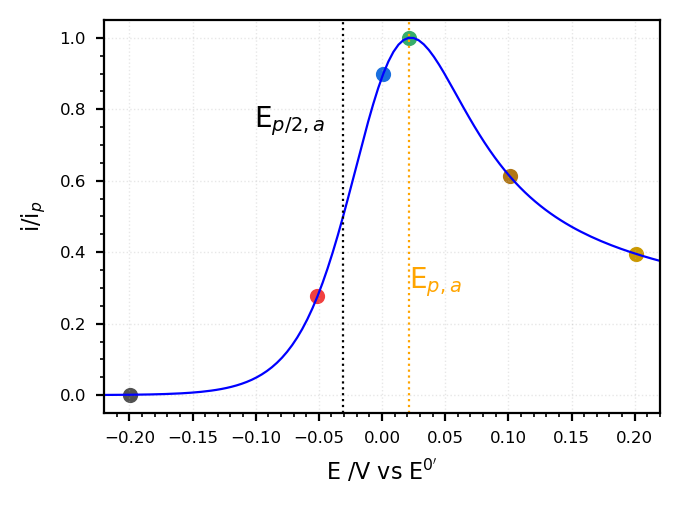

In [2]:
# The semi-infinite diffusion result we are about to break.
demo_cv = np.genfromtxt('../Resources/data/demo_cv.csv', delimiter=',', skip_header=1)
demo_e = demo_cv[:, 0]
demo_i = demo_cv[:, 1]
SELECTED_E = [-0.2, -0.05, 0.0, 0.021, 0.1, 0.2]

fig = plt.figure()
ax = plt.subplot()
echem.annotate_demo_cv(ax, demo_e, demo_i, marked_potentials=SELECTED_E)

fig.savefig('../Workspace/finitediffusion-lsv.png')

We saw that the key assumption underlying semi-infinite diffusion was:

$
\large \lim_{x \to \infty} C_O(x,t) = C_O^*
$

And that this yielded a characteristic shape for the E-i data. For cyclic voltammetry:

$
\large i_p = 2.69x10^5 n^\frac{3}{2} A \sqrt{D_i \nu} C_i
$

$
\large \frac{i_{p,a}}{i_{p,c}} = 1.0
$

$
\large E_p - E_\frac{1}{2} = \frac{28.5 mV}{n}
$

$
\large E_\frac{p}{2} - E_\frac{1}{2} = \frac{28.0 mV}{n}
$

$
\large E_p - E_\frac{p}{2} = \frac{56.5 mV}{n}
$

<div class="alert alert-block alert-danger">
<b>Memory Check:</b>  In layman terms, describe what the semi-infinite diffusion approximation is. For the figure above, verbally describe (i) the starting conditions, (ii) why the data takes on a peak shape, and which reactions are taking place at which potentials.
</div>


**What happens if the assumption of semi-infinite diffusion fails?**

Consider our generic situation for a simple reaction:

$
\large O + e^- \rightleftharpoons R
$

In the condition where only $O$ is initially present and a potential step is applied such that $E << E^0$:

In [3]:
# What happens when a wall stops the diffusion layer growing.
# Column 0 of the file is x/sqrt(D t); the first 108 rows cover the region of interest.
data = np.genfromtxt('../Resources/data/conc_profile.csv', delimiter=',', skip_header=1)
NEAR_ELECTRODE = slice(None, 108)
x_dimensionless = data[NEAR_ELECTRODE, 0]
c_reduced = data[NEAR_ELECTRODE, 1]
c_oxidized = data[NEAR_ELECTRODE, 2]

@interact(s=widgets.RadioButtons(options=[1, 2, 3, 4], description='step'))
def plot_finite_diffusion(s):
    '''Step through what a thin layer cell does to a concentration profile.'''
    fig = plt.figure()
    ax = plt.subplot()
    ax.axvline(0.0055, linewidth=20, color='black')     # the far wall
    distance = x_dimensionless*0.001

    if s > 0:       # initial conditions: all O, no R
        ax.plot(distance, np.ones(distance.size), c='black')
        ax.plot(distance, np.zeros(distance.size), c='red')
    if s > 1:       # short times: an ordinary growing diffusion layer
        ax.plot(distance, c_reduced, c='black', linestyle='--')
        ax.plot(distance, c_oxidized, c='red', linestyle='--')
    if s > 2:       # long times: the layer has reached the wall
        ax.plot(distance, c_reduced/2, c='black', linestyle='-.')
        ax.plot(distance, 1 - c_reduced/2, c='red', linestyle='-.')
    if s > 3:       # complete electrolysis: nothing left to convert
        ax.plot(distance, np.zeros(distance.size), c='black', linestyle=':')
        ax.plot(distance, np.ones(distance.size), c='red', linestyle=':')

    ax.annotate(r'$C_O/C_T^*$', (0.0065, 1.0), color='black', fontsize=6)
    ax.annotate(r'$C_R/C_T^*$', (0.0065, 0), color='red', fontsize=6)
    ax.annotate('', fontsize=8, xy=(0, 1.05), xycoords='data',
                xytext=(0.005, 1.05), textcoords='data',
                arrowprops=dict(arrowstyle='<->', color='gray'))
    ax.annotate(r'$l$', (0.0025, 1.1), color='gray', fontsize=6)

    ax.set_xlabel('distance /cm')
    ax.set_xlim(left=0, right=0.008)
    ax.set_ylabel(r'$C_j/C_T^*$')
    ax.set_ylim(-0.1, 1.2)

interactive(children=(RadioButtons(description='step', options=(1, 2, 3, 4), value=1), Output()), _dom_classes…

# 2. The Fully Reversible Situation

The situation must be handled as previously done: a series of assumptions need to be made in order to establish **boundary conditions** - mathematical conditions that allow us to solve the partial differential equation describing how current changes with time. 

We will follow the same approach as the course textbook, which uses a solution containing only $O$ as the starting point. The first step will be to remove dependence on $x$. This means that the timeframe on which we probe the system is large enough that x is irrelevant. Namely, we are in step 4 in the above figure.

For $\large 0 \leq x \leq l$:

$
\large C_O(x,t) = C_O (t)
$

$
\large C_R(x,t) = C_R(t)
$

For a linear sweep experiment (including cyclic voltammetry), we can define:

1. Reaction rate: we are now working in 3-dimensions so volume ($V$) becomes important:

$
\large i = -nFV\left[ \frac{dC_O(t)}{dt} \right]
$

2. Thermodynamics: note the removal of x-dependence

$
\large E = E^{0'} + \frac{RT}{nF}ln\left(\frac{C_O(t)}{C_R(t)} \right)
$

3. Conservation of mass:

$
\large C_O^* = C_O(t) + C_R(t)
$

Following Laplace transforms on these conditions, one acquires the general current-voltage behavior:

$
\large i = \frac{n^2F^2 \nu V C_O^*}{RT}\frac{\theta}{[1+\theta]^2}
$

Where $\theta$ is the exponential form of the Nernst equation:

$
\large \theta = e^{nf\eta}
$

Visualization of this expected behavior:

In [4]:
@interact(n=widgets.IntSlider(value=1, min=1, max=4, description=r'$n$'),
          scan_rate=widgets.FloatText(value=0.001, description=r'$\nu$ /V s$^{-1}$'),
          volume=widgets.FloatText(value=1e-3, description=r'$V /cm^{3}$'),
          conc=widgets.FloatText(value=1e-6, description=r'$C_O^* / mol\,cm^{-3}$'))
def plot_thin_layer_reversible(n, scan_rate, volume, conc):
    '''A symmetric peak that comes from EXHAUSTION, not from mass transport.

    Note what n does: it raises the peak as n^2 AND narrows it, because the
    Nernstian term carries n as well.  Peak width at half height is 90.6/n mV.
    '''
    if min(scan_rate, volume, conc) <= 0:
        print('Scan rate, volume and concentration must all be greater than zero.')
        return
    potential = np.linspace(0.3, -0.3, 201)
    current = echem.thin_layer_reversible(potential, scan_rate, volume, conc, n=n)

    # mirror the sweep to show both directions
    potential_cv = np.append(potential, potential[::-1])
    current_cv = 1e6*np.append(current, -current[::-1])     # A -> microamps

    fig = plt.figure()
    ax = plt.subplot()
    ax.plot(potential_cv, current_cv)
    ax.set_xlabel(r"$E$ /V vs. $E^{0'}$")
    ax.set_ylabel(r'$i$ /$\mu$A')
    ax.set_title(rf'$i_p$ = {1e6*current.max():.2f} $\mu$A', fontsize=8)

    fig.savefig('../Workspace/finitediffusion_CV.png')

interactive(children=(IntSlider(value=1, description='$n$', max=4, min=1), FloatText(value=0.001, description=…

Once again, the sweep generates a peak shape. It should be obvious from the general equation that the peak current is observed at:

$
\large i_p = \frac{n^2 F^2 \nu V C_O^*}{4RT}
$

This situation is different, however, in that the peak shape **does not arise due to mass transfer**. Rather, it emerges because the reactant is completely consumed. This is apparent in the symmetry of the peak and the fact that it decays to zero current. This behavior yields a number of metrics that can be used to diagnose reversibility:

$
\large i_{p,a} = -i_{p,c}
$

$
\large E_{p,c} = E_{p,a} = E_{1/2}
$

$
\large  \Delta E_p = 0
$

$
\large \Delta E_{p, 1/2} = \frac{90.6}{n}
$ mV

# 3. Introducing Electrochemical Irreversibility

The rate of reaction can be defined in two ways:

$
\large i = -nFV\left[ \frac{dC_O(t)}{dt} \right]
$

$
\large  i = nFAk_fC_O(t)
$

Combination of these equations yields:

$
\large \frac{dC_O(t)}{dt} = -\frac{Ak_f}{V}C_O(t)
$

As we have seen, the rate constant $k_f$ is dependent on potential.

$
\large k_f = k^0 e^{-\alpha f (E - E^{0'})}
$

The potential, in turn, is dependent on time through the scan rate, $\nu$:

$
\large E = E_i - \nu t
$

Therefore:

$
\large k_f = k^0 e^{-\alpha f (E_i - E^{0'})}e^{\alpha f \nu t }
$

Following the necessary Laplace transforms, one obtains:


$
\Large i(E) = FAk_fC_O^* e^{-\frac{RT}{\alpha F} \frac{Ak_f}{V\nu}}
$

Note that the exponential contains a new **dimensionless parameter** for reaction rate:

$
\large \frac{Ak^0}{\alpha fV\nu}
$

Expanding the equation to its full glory, we have:

$
\Large i(E) = FAk^0C_O^* e^{\left[ -\alpha f (E-E^{0'}) - \frac{Ak^0}{\alpha fV\nu}e^{-\alpha f (E-E^{0'})}\right]}
$



In [5]:
@interact(k_0=widgets.FloatLogSlider(value=1e-6, min=-10, max=-5, description=r'$k^0$'),
          alpha=widgets.FloatSlider(value=0.5, min=0.1, max=0.9, step=0.02,
                                    description=r'$\alpha$'),
          scan_rate=widgets.FloatText(value=0.002, step=0.001, description=r'$\nu$'),
          volume=widgets.FloatText(value=2e-6, description=r'$V /cm^{3}$'),
          area=widgets.FloatText(value=0.5, description=r'$A /cm^{2}$'),
          conc=widgets.FloatText(value=1e-6, description=r'$C_O^* / mol\,cm^{-3}$'),
          e_i=widgets.FloatText(value=0.4, description=r'$E_i$'),
          e_f=widgets.FloatText(value=-1.2, description=r'$E_f$'))
def plot_thin_layer_irreversible(k_0, alpha, e_i, e_f, scan_rate, volume, area, conc):
    '''Slow kinetics in a thin layer: the peak loses its symmetry and drifts.'''
    if min(scan_rate, volume, area, conc) <= 0 or e_i == e_f:
        print('All the physical settings must be positive and E_i must differ from E_f.')
        return
    potential = np.linspace(e_i, e_f, 301)
    current = 1e6*echem.thin_layer_irreversible(potential, scan_rate, volume,
                                                area, conc, k_0, alpha=alpha)

    fig = plt.figure()
    ax = plt.subplot()
    ax.plot(potential, current)
    ax.set_xlabel(r"$E$ /V vs. $E^{0'}$")
    ax.set_ylabel(r'$i$ /$\mu$A')
    ax.set_xlim(potential.max(), potential.min())

    # NOTE: save AFTER plotting, or the file contains empty axes.
    fig.savefig('../Workspace/finitediffusion_quasirev.png')

interactive(children=(FloatLogSlider(value=1e-06, description='$k^0$', max=-5.0, min=-10.0), FloatSlider(value…

<div class="alert alert-block alert-info">
<b>Activity:</b> Use the interactive figure above to deduce the effect that each of the parameters has on the observed behavior. Pay particular attention to the kinetic parameters.
</div>

Overall, the electrochemically irreversible peaks should be characterized by:

$
\large E_p = E^{0'} + \frac{RT}{\alpha F}ln\left[ \frac{A k^0}{\alpha f V \nu} \right]
$

$
\large i_p = \frac{\alpha F^2 V \nu C_O^*}{2.718 RT}
$

The kinetic parameters may not have had the effect that you anticipated. What is expected is that changes in $k^0$ relative to $\nu$ is a shift in peak location:

<img src='../Resources/images/finitediffusion-k0.png' width=60%>

While changes in $\alpha$ change the shape of the peak:

<img src='../Resources/images/finitediffusion-alpha.png' width=60%>

<div class="alert alert-block alert-info">
<b>Activity:</b> Create a list of experiments where you might expect to see <b>finite diffusion conditions</b>
</div>

Finite diffusion conditions may be observed in:
1. xxx
2. yyy


# 4. Electroactive Layers and Chemically Modified Electrodes

Deposition of an electroactive monolayer onto an electrode surface results in behavior that is reminiscent of finite diffusion. The terminology, however, changes. Concentration becomes 2-dimensional surface coverage, represented by $\Gamma_j$. The current-voltage relationship expected is:

$
\large i = \frac{n^2F^2}{RT} \frac{\nu A \Gamma^*(b_o/b_R)e^{nf\eta}}{[1+ (b_o/b_R)e^{nf\eta}]^2}
$

Where the $b_j$ parameters represent:

$
\large b_j = \Gamma_{j,s}\beta_j
$

This term captures the thermodynamics for adsorption isotherms. We won't go into too much detail on adsorption isotherms, but it is important to understand the basic concept and options available. The species adsorbing to the surface is a chemical reaction: species $j$ can exist in a solvated form (in phase B) or a surface bound form (phase A). The activity of the species is defined as:

$
\large a_j^A = \beta_ja_j^B
$

Where:

$
\large \beta_j = e^{-\Delta G_{ads}^0/RT}
$

From here, there are several different common models to choose from.

## Langmuir Isotherms

Langmuir isotherms are the simplest form available. They assume:
1. no interactions between adsorbed species
2. no heterogeneity on the surface on which the species adsorbs
3. electrode saturation at high activity of $j$ in the adjacent solution

Under these assumptions:

$
\large \Gamma_j = \frac{\Gamma_s \beta_j C_j}{1+\beta_j C_j}
$

Where $\Gamma_s$ is the saturated surface concentration. Being a thermodynamic feature, it should not be surprising that adsorption will have a significant effect on observed behavior:

<img src='../Resources/images/langmuir.png' width=50%>

## Interactions Between Adsorbed Species

There are two common approaches to consider possible interactions between neighboring adsorbed species.

#### Temkin Isotherm

It is assumed that there is no limiting coverage on the surface. A new empirical term, $g$, is introduced to describe the strength of interaction between neighboring species:

$
\large \Gamma_j = \frac{RT}{2g}ln(\beta_jC_j)
$

#### Frumkin Isotherm

A blend of both concepts, where limiting coverage is observed, but there are also interactions between neighbors:

$
\large \beta_j a_j^B = \frac{\Gamma_j}{\Gamma_s - \Gamma_j}e^{\frac{2g\Gamma_i}{RT}}
$

<img src='../Resources/images/frumkin.png' width=50%>

Given the range of possible interactions and sequences of events, there are a large number of possible behaviors to observe. For example:

If the **product** of a simple electron transfer reaction is adsorbed to the surface:

<img src='../Resources/images/productadsorbed.png' width=50%>

If the **reactant** for a simple electron transfer reaction is adsorbed to the surface:

<img src='../Resources/images/reactantadsorbed.png' width=30%>

---
# Literature Examples

Electroactive layers on electrodes and intentionally modified electrodes factor heavily into electrocatalysis. Thin metal oxide films, for example: [Science 2013, 340, 60-63](http://doi.org/10.1126/science.1233638)

<img src='../Resources/images/ecatalysis.png' width=50%>


Chemically modified electrodes with electroactive species such as ferrocene provide insight into fundamental chemistry: [Chem. Rev. 2016, 116, 4808](https://doi.org/10.1021/acs.chemrev.5b00595)

<img src='../Resources/images/surfaceFc.png' width=50%>

There are many, many more examples that span photovoltaics, battery materials, fuel cells and more.

<div class="alert alert-block alert-info">
<b>Activity:</b> Under semi-infinite diffusion $i_p \propto \sqrt{\nu}$; in a thin layer cell $i_p \propto \nu$.
<br>
Design the experiment that would tell you which regime a real sample is in, and state exactly what you would plot. This is a diagnostic you will use on your own data.
</div>

- What I would vary: ANSWER
- What I would plot: ANSWER
- What the two outcomes would look like: ANSWER